In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/0
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))


# 第0章 OSって個人で作れるの？ — 0.2 そもそもOSって何？ (*What is an Operating System?*)

---

## 1. 導入：OSが存在しない「ベアメタル」の世界を想像する

現代のプログラミングでは、Python で `print("Hello, World!")` と書いたり、C++ で `std::cout << ...` と書くだけで、画面に当たり前のように文字が表示されます。ファイルを開いてデータを書き込むことも、ネットワーク経由で Web サーバーと通信することも、わずか数行のコードで実現できます。

しかし、もしコンピュータ上に **オペレーティングシステム (*Operating System: OS*)** が一切存在しなかったらどうなるでしょうか？

CPU の電源を入れた直後の状態（これを **ベアメタル (*Bare Metal: むき出しの金属*)** と呼びます）では、画面もファイルもネットワークも存在しません。あるのは、物理アドレス空間に配置された数千万〜数十億のトランジスタ、各種デバイスの制御用レジスタ（**MMIO: Memory-Mapped I/O** や **I/Oポート**）、そして CPU が愚直にフェッチ・デコード・実行を繰り返す機械語命令だけです。

この過酷な物理ハードウェアの世界と、人間が快適に扱えるソフトウェアの世界の間に立ち、橋渡しを行う巨大な基盤ソフトウェアこそが **OS** です。

書籍『ゼロからのOS自作入門』において、OSの存在意義は以下の **2大基本機能** に集約されます：

1. **ハードウェアの抽象化 (*Hardware Abstraction*)**: 複雑怪奇なハードウェア固有の制御手順を隠蔽し、扱いやすい共通インターフェース（API / システムコール）を提供する。
2. **リソースの管理 (*Resource Management*)**: 複数のアプリケーションが同時に動作する環境で、CPU・メモリ・ストレージ・画面などの物理リソースが衝突しないよう安全かつ公平に調停・分配する。


---

### 0.2.1 ハードウェアの抽象化 (*Hardware Abstraction*)

#### なぜ抽象化が必要なのか？
パソコンに搭載されているハードウェアは、メーカーや製品ごとに仕様がまったく異なります。
- **画面表示**: Intel 内蔵グラフィックス、NVIDIA GeForce、AMD Radeon では、VRAM の制御コマンドも 2D/3D 加速機構も完全に別物です。
- **ストレージ**: NVMe SSD、SATA HDD、USB メモリ、SD カードでは、データを読み書きするための通信プロトコル（パケット構造、コマンドキュー）が根本から異なります。
- **ネットワーク**: Intel 製 Ethernet カードと Realtek 製 Wi-Fi チップでは、パケットの送受信レジスタの配置が一切共通していません。

もし OS が存在しなければ、アプリケーション開発者は「この SSD 用の読み書きドライバ」「このディスプレイ用のピクセル描画ドライバ」を自前で実装しなければならず、世の中のすべてのハードウェアに対応したソフトウェアを作ることは実質的に不可能です。

#### OSによる抽象化の仕組み
OS は、これらハードウェア固有の制御コードを **デバイスドライバ (*Device Driver*)** として内部に抱え込み、アプリケーションに対しては極めてシンプルで抽象的なインターフェースを提供します。

```mermaid
flowchart TD
    App["アプリケーション (Application)"] -->|抽象化API: write() / print()| VFS["仮想ファイルシステム / 入出力抽象化層\n(VFS / Hardware Abstraction Layer)"]
    VFS -->|ブロック読み書き| D1["NVMe / SATA ドライバ"]
    VFS -->|USB パケット転送| D2["xHCI USB ドライバ"]
    VFS -->|フレームバッファ描画| D3["GOP / グラフィックスドライバ"]
    D1 --> HW1["物理 SSD / HDD"]
    D2 --> HW2["物理 USB メモリ / マウス"]
    D3 --> HW3["物理 ディスプレイ (VRAM)"]
```

例えば UNIX 哲学における **「すべてはファイルである (*Everything is a File*)」** という格言は、ハードウェア抽象化の究極の具現化です。SSD 上のテキストファイルも、キーボードからの入力も、画面への文字出力も、すべて `open()` して `read()` / `write()` して `close()` するという共通のバイトストリームとして扱えるようになります。


---

### 0.2.2 リソースの管理 (*Resource Management*)

OS のもうひとつの決定的な役割が、物理ハードウェア資源（リソース）の調停と保護です。

現代の PC では、ブラウザ、エディタ、音楽プレーヤ、バックグラウンドデーモンなど、無数のプログラムが同時に実行されます。もしこれらが直接ハードウェアを操作できたとすると、悲劇的な事態が発生します：

1. **メモリの破壊 (*Memory Corruption*)**:
   - プログラム A のバグによって、プログラム B のメモリや OS 自身の重要なデータ構造が上書きされ、システム全体がクラッシュする。
2. **CPU 時間の独占 (*CPU Starvation*)**:
   - 1つのプログラムが `while (true) {}` の無限ループに陥ると、他のすべてのプログラムが停止し、PC が完全にフリーズする。
3. **画面やデバイスの衝突 (*Device Contention*)**:
   - 複数のアプリが同時に画面の同じピクセル領域に描画を始め、画面表示がぐちゃぐちゃに破壊される。

#### OSが提供する3大管理機構

| 管理対象 | OSの制御機構 | MikanOS での実装章 | 本質的な役割 |
|:---:|---|:---:|---|
| **メモリ** | **仮想記憶 & ページング (*Paging*)** | 第8章, 第19章, 第27章 | 各プロセスに独立した 48ビット仮想アドレス空間を与え、他プロセスのメモリ読み書きをハードウェアレベルで完全遮断する。 |
| **CPU時間** | **マルチタスク & スケジューラ (*Scheduler*)** | 第13章, 第14章 | タイマ割り込みにより CPU の実行権限を定期的に強制奪還（プリエンプション）し、時分割多重で複数のタスクを並行動作させる。 |
| **画面・入力** | **レイヤマネージャ & イベントキュー** | 第6章, 第9章, 第10章, 第15章 | 各ウィンドウを独立したオフスクリーンバッファに描画させ、OS が前後関係（Z-order）を考慮して合成・表示する。 |

特に x86-64 アーキテクチャでは、CPU 自体が **特権レベル (*Privilege Levels / Rings*)** をハードウェアとしてサポートしています：
- **Ring 0 (特権モード / Supervisor Mode)**: OS カーネルが動作するモード。全機械語命令（`CLI`, `STI`, `HLT`, `MOV CR3` 等）の実行、全物理メモリへのアクセスが可能。
- **Ring 3 (非特権モード / User Mode)**: 一般のアプリケーションが動作するモード。ハードウェア直接操作命令やカーネル専用メモリへのアクセスがハードウェアにより禁止されており、違反すると CPU 例外（一般保護例外 `#GP` やページフォルト `#PF`）が発生して OS に捕捉・強制終了されます。


---

### 0.2.3 カーネルとシェル、そしてシステムコール (*Kernel, Shell & System Calls*)

一般に「OS」と呼ばれるソフトウェア群は、大きく **カーネル (*Kernel*)** と **シェル (*Shell*) / ユーザーランド (*Userland*)** に分類されます。

```mermaid
flowchart TD
    subgraph UserSpace["ユーザー空間 (Ring 3: 非特権モード)"]
        App1["GUI アプリケーション (お絵描き / ブロック崩し)"]
        App2["CLI コマンド (echo / cat / grep / rpn)"]
        Shell["シェル / ターミナルウィンドウ (Terminal Task)"]
        LibC["C標準ライブラリ (Newlib: printf, malloc, exit)"]
        App1 & App2 & Shell --> LibC
    end

    LibC -->|SYSCALL 命令| Gate{"CPU 特権境界\n(Hardware Transition Ring 3 → 0)"}

    subgraph KernelSpace["カーネル空間 (Ring 0: 特権モード - MikanOS Core)"]
        Gate --> SysEntry["SyscallEntry (アセンブリ)"]
        SysEntry --> Dispatch["syscall_table ディスパッチ"]
        Dispatch --> ModMem["メモリ管理 (ページテーブル / sbrk)"]
        Dispatch --> ModTask["タスクスケジューラ (マルチタスク)"]
        Dispatch --> ModGUI["レイヤマネージャ (Window 合成)"]
        Dispatch --> ModFS["FAT32 ファイルシステム"]
    end

    SysEntry -.->|SYSRET 命令 (Ring 0 → 3)| LibC
```

- **カーネル (*Kernel*)**: OS の中核部。Ring 0 で常駐し、ハードウェア抽象化とリソース管理のすべてを司る。本書で自作していく主役です。
- **シェル (*Shell*)**: ユーザーが入力したコマンド（`echo`, `ls`, `cat` 等）を受け取り、解釈して該当するアプリケーションの ELF バイナリをファイルシステムから探して実行するインターフェースプログラム（Ring 3 で動作）。
- **システムコール (*System Call*)**: Ring 3 のアプリケーションが、Ring 0 のカーネルに対して「画面に文字を表示してほしい」「ファイルを読んでほしい」「メモリを割り当ててほしい」と正式に要求するための唯一の安全な窓口です。


In [2]:
# C++20 による OS 階層モデルとシステムコールディスパッチャの実装・コンパイル・実行
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
cpp_source = repo_root / "src" / "ch00" / "os_posix_architecture.cpp"
bin_dir = repo_root / "bin"
bin_dir.mkdir(exist_ok=True)
bin_path = bin_dir / "os_posix_architecture"

# ホスト環境の g++ (C++20) でスタンドアロン検証バイナリをコンパイル
compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-Wpedantic",
    str(cpp_source), "-o", str(bin_path)
]
print(f"Compiling {cpp_source.name} with C++20...")
comp_res = subprocess.run(compile_cmd, capture_output=True, text=True)
if comp_res.returncode != 0:
    print("❌ Compilation Error:\n", comp_res.stderr)
else:
    print("✅ Compilation Successful! Executing simulated kernel & userland...")
    exec_res = subprocess.run([str(bin_path)], capture_output=True, text=True)
    print("\n--- [C++20 Program Output] ---")
    print(exec_res.stdout)


Compiling os_posix_architecture.cpp with C++20...


✅ Compilation Successful! Executing simulated kernel & userland...

--- [C++20 Program Output] ---
=== Section 0.2: OS Architecture, POSIX & System Call Dispatching (C++20) ===
[+] Hardware Abstraction Test Passed: Wrote 44 bytes to stdout.
[+] Protection Check Passed: Invalid file descriptor rejected by kernel.
[+] Memory Safety Check Passed: Null buffer pointer gracefully rejected (-EFAULT).
[+] Process Control Passed: App terminated with exit code 42 via SyscallExit.

[Summary]
- Ring 3 (User App) communicates with Ring 0 (Kernel) strictly via system calls.
- Hardware I/O details are abstracted behind POSIX-compliant standard C library functions.
- CPU privilege rings guarantee that faulty user apps cannot corrupt OS internal state.



---

### コラム0.1: OSの仕様とPOSIX (*Portable Operating System Interface*)

#### POSIXの誕生背景と「UNIX戦争」
1970年代から1980年代にかけて、ベル研究所で誕生した UNIX は世界中に普及しましたが、やがてカリフォルニア大学バークレー校の **BSD (*Berkeley Software Distribution*)** 系と、AT&T の **System V** 系に大きく分裂しました（**UNIX戦争: Unix Wars**）。

両者は同じ「UNIX」を名乗りながらも、システムコールの関数名、引数の順序、シグナル処理の挙動、ディレクトリ構造などが微妙に異なっていました。その結果、BSD 向けに書かれた C 言語プログラムが System V ではコンパイルエラーになったり、実行時に予期せぬ暴走を引き起こすという深刻な「移植性 (*Portability*) の喪失」が発生しました。

この混乱を収拾するため、1980年代後半に **IEEE (*Institute of Electrical and Electronics Engineers*)** と **ISO/IEC** によって策定された国際標準規格が **POSIX (*Portable Operating System Interface*)**（IEEE Std 1003.1）です。
なお、「POSIX」という名称は、GNU プロジェクト創始者の **リチャード・ストールマン (*Richard Stallman*)** が提唱したものです。

#### POSIXが規定する主なインターフェース

| カテゴリ | 代表的な POSIX API / 仕様 | 役割・機能 |
|---|---|---|
| **ファイルI/O** | `open`, `read`, `write`, `close`, `lseek`, `stat` | ファイルやデバイスに対する低水準バイトストリーム操作 |
| **プロセス制御** | `fork`, `execve`, `waitpid`, `exit`, `getpid` | プロセスの複製、別プログラムのロード実行、終了待機 |
| **シグナル** | `kill`, `sigaction`, `sigprocmask` | 非同期イベント（Ctrl+C 等）の通知と割り込みハンドリング |
| **メモリ管理** | `mmap`, `munmap`, `mprotect` | ファイルのメモリマッピング、ページ単位の動的保護 |
| **スレッド制御** | `pthread_create`, `pthread_join`, `pthread_mutex_*` | POSIX Threads (pthreads) によるマルチスレッド並行処理 |
| **標準コマンド** | `sh`, `ls`, `cp`, `mv`, `grep`, `awk`, `sed` | POSIX 準拠シェルおよびユーティリティコマンドの挙動仕様 |

#### MikanOS における POSIX の位置づけ
自作 OS を学ぶ上で、**「どこまで標準仕様（POSIX）に準拠すべきか？」** は極めて重要な設計判断となります。

1. **完全準拠を目指さない理由**:
   - POSIX を完全に満たそうとすると、`fork()`（メモリ空間の完全複製と Copy-on-Write）、複雑なシグナル配信機構、パーミッション管理（UID/GID）、端末制御（termios）など、膨大な実装コストがかかります。これらは学習用のフルスクラッチOSにとっては過度な負担となります。
2. **C標準ライブラリ（Newlib）との連携による実用性の獲得**:
   - MikanOS では、組み込み・自作OS向けに広く使われている軽量C標準ライブラリ **Newlib** を移植しています。
   - Newlib は、OS ごとに異なるシステムコールの差分をわずか数個の「システムコールスタブ関数」（`_write`, `_read`, `_sbrk`, `_exit`, `_close` 等）に集約して要求します。
   - MikanOS のカーネル側にこれらのスタブ関数（`syscall.asm` / `newlib_support.c`）を配備することで、アプリケーション側からは C標準の `printf()`, `sprintf()`, `malloc()`, `exit()` や C++ の `std::vector` などが何の違和感もなくそのまま利用できるようになっています。


Generated: /home/student/Documents/GitHub/study-mikanos/0/result/fig0_3_os_architecture_layers.png (452.3 KB)


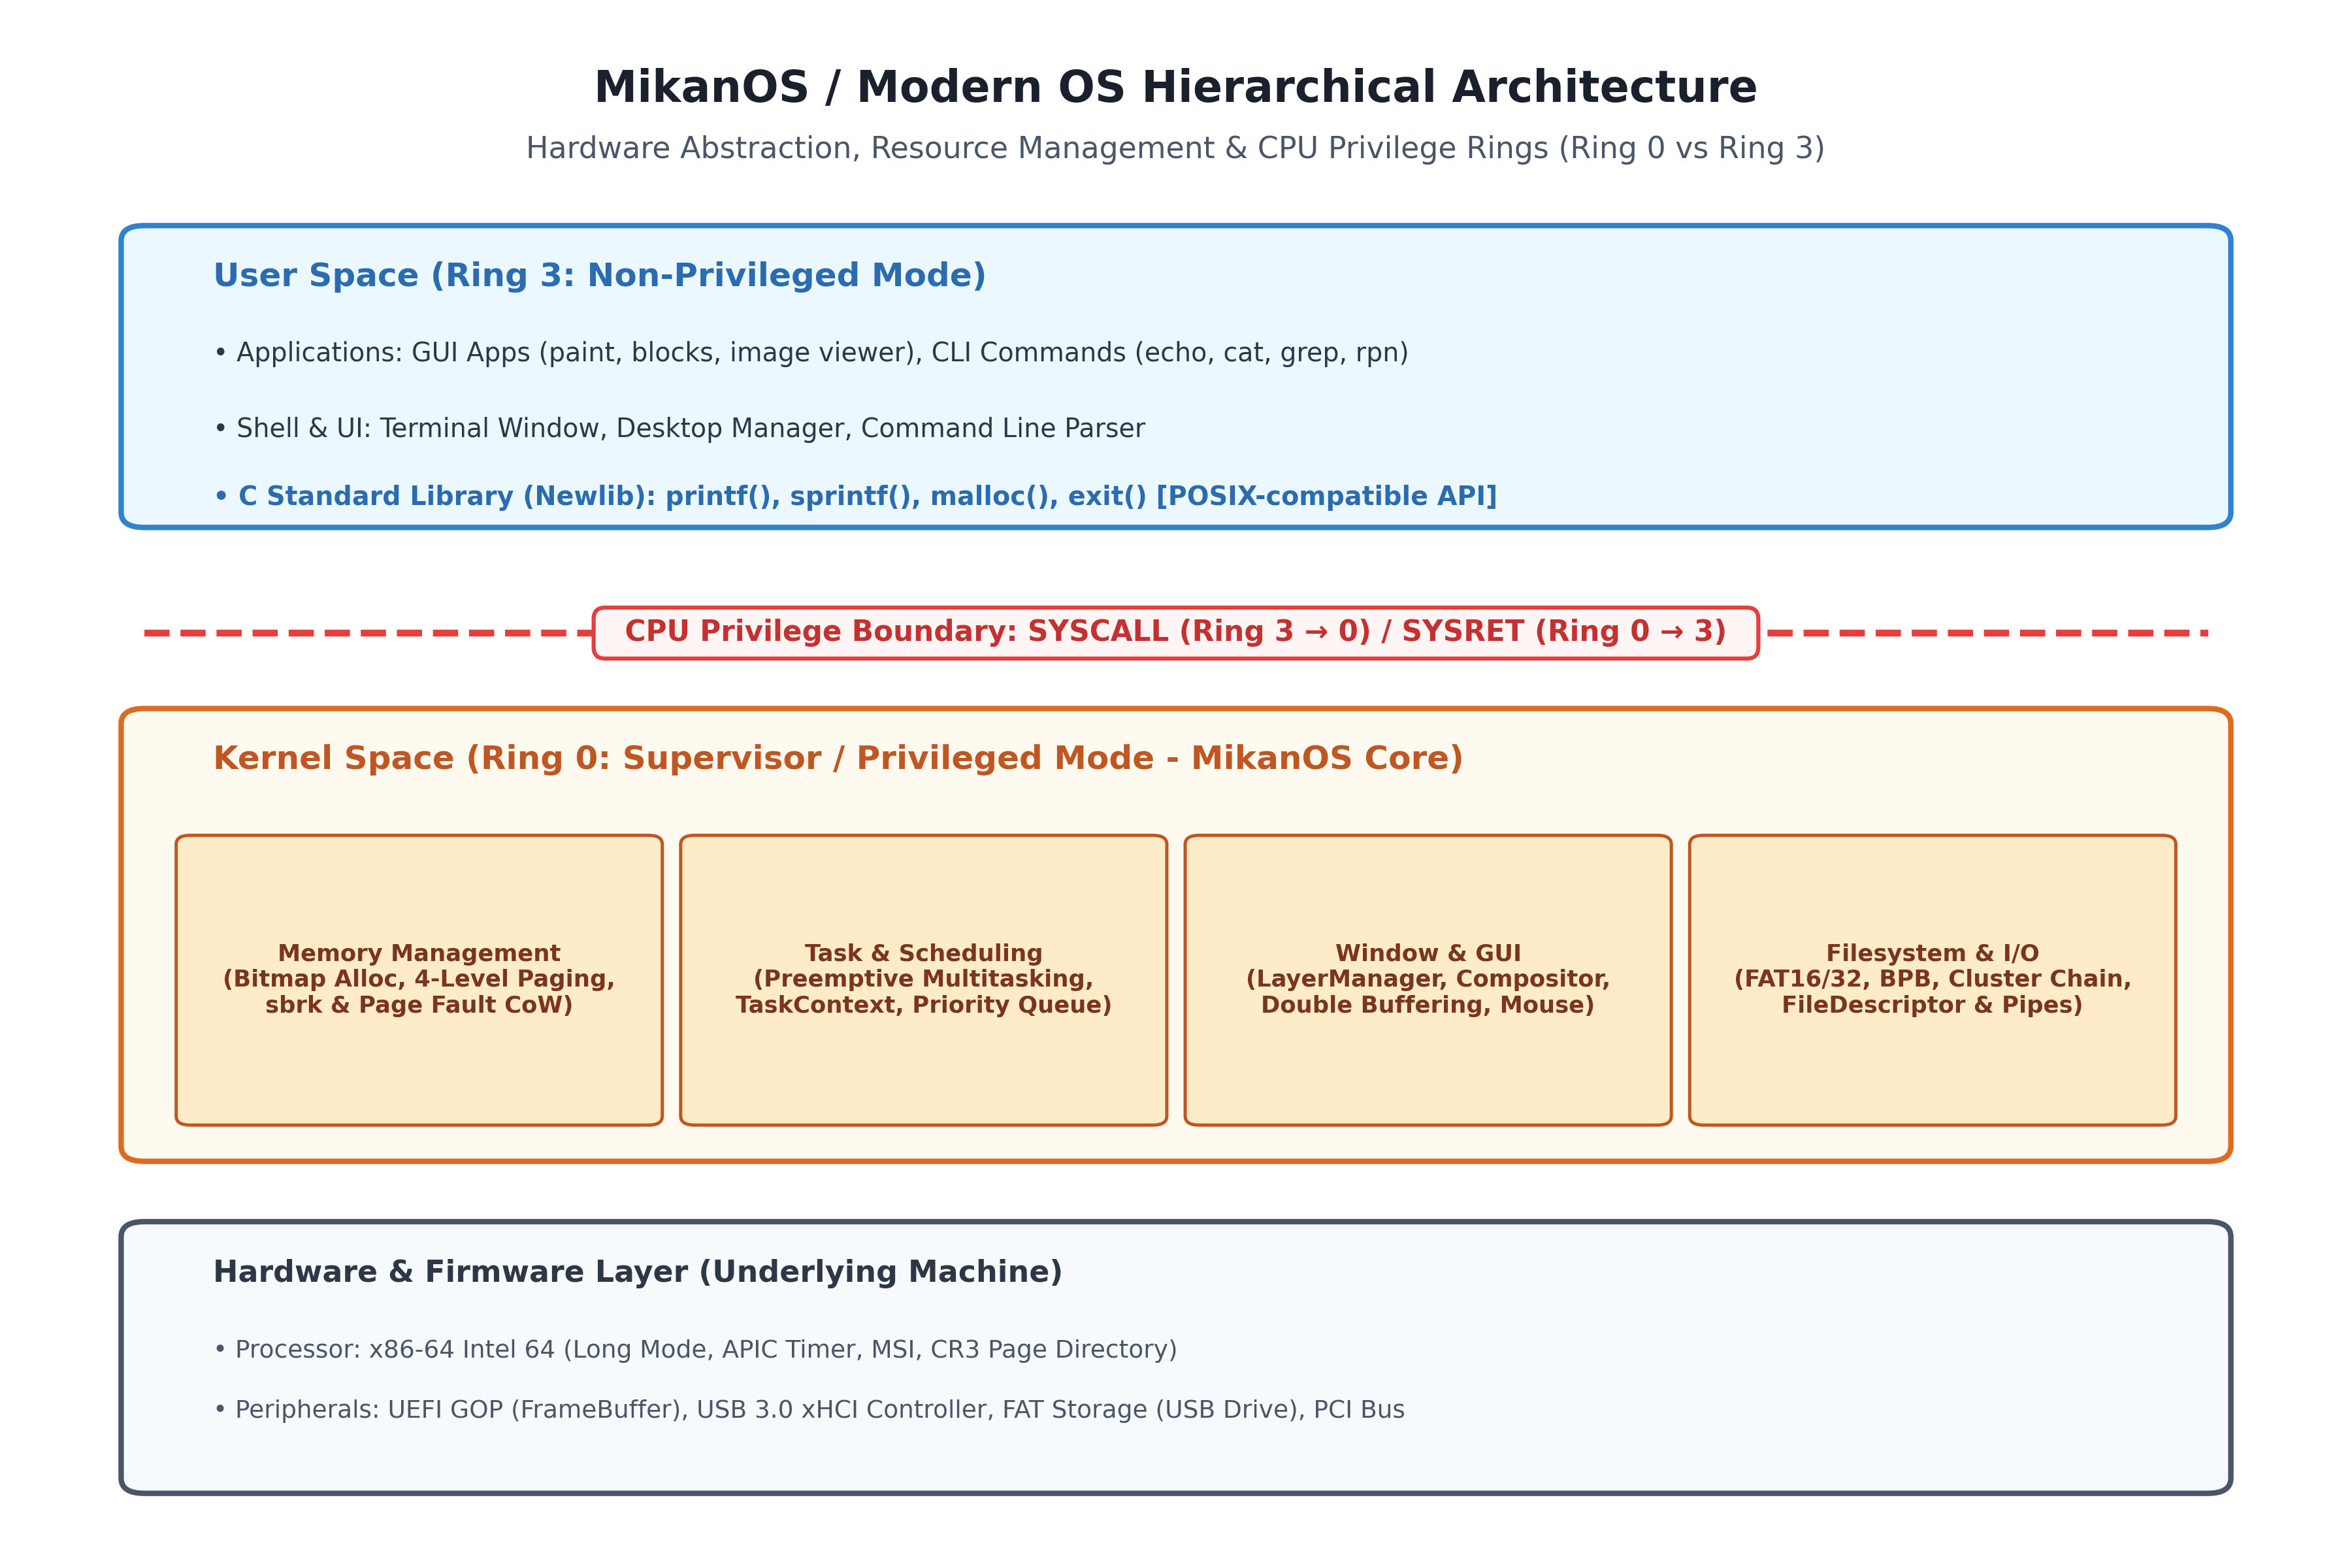

In [3]:
# 図版生成 1: OSの階層アーキテクチャ図（ユーザー空間、カーネル空間、ハードウェア抽象化層）
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)
out_path = result_dir / "fig0_3_os_architecture_layers.png"

fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Title
ax.text(50, 96, "MikanOS / Modern OS Hierarchical Architecture",
        fontsize=16, fontweight="bold", ha="center", va="center", color="#1a202c")
ax.text(50, 92, "Hardware Abstraction, Resource Management & CPU Privilege Rings (Ring 0 vs Ring 3)",
        fontsize=11, ha="center", va="center", color="#4a5568")

# Layer 1: Userland / Applications (Ring 3)
rect1 = patches.FancyBboxPatch((5, 68), 90, 18, boxstyle="round,pad=1",
                               facecolor="#ebf8ff", edgecolor="#3182ce", linewidth=2)
ax.add_patch(rect1)
ax.text(8, 83, "User Space (Ring 3: Non-Privileged Mode)", fontsize=12, fontweight="bold", color="#2b6cb0")
ax.text(8, 78, "• Applications: GUI Apps (paint, blocks, image viewer), CLI Commands (echo, cat, grep, rpn)", fontsize=9.5, color="#2d3748")
ax.text(8, 73, "• Shell & UI: Terminal Window, Desktop Manager, Command Line Parser", fontsize=9.5, color="#2d3748")
ax.text(8, 68.5, "• C Standard Library (Newlib): printf(), sprintf(), malloc(), exit() [POSIX-compatible API]", fontsize=9.5, color="#2b6cb0", fontweight="semibold")

# System Call Boundary (Hardware Protection Wall)
ax.axhline(60, xmin=0.05, xmax=0.95, color="#e53e3e", linestyle="--", linewidth=2.5)
ax.text(50, 60, "  CPU Privilege Boundary: SYSCALL (Ring 3 → 0) / SYSRET (Ring 0 → 3)  ",
        fontsize=10.5, fontweight="bold", color="#c53030", ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#fff5f5", edgecolor="#e53e3e", linewidth=1.5))

# Layer 2: Kernel Space (Ring 0)
rect2 = patches.FancyBboxPatch((5, 26), 90, 28, boxstyle="round,pad=1",
                               facecolor="#fffaf0", edgecolor="#dd6b20", linewidth=2)
ax.add_patch(rect2)
ax.text(8, 51, "Kernel Space (Ring 0: Supervisor / Privileged Mode - MikanOS Core)",
        fontsize=12, fontweight="bold", color="#c05621")

# Subsystems in Kernel
boxes = [
    ("Memory Management\n(Bitmap Alloc, 4-Level Paging,\nsbrk & Page Fault CoW)", 7, 28, 20, 18, "#feebc8", "#c05621"),
    ("Task & Scheduling\n(Preemptive Multitasking,\nTaskContext, Priority Queue)", 29, 28, 20, 18, "#feebc8", "#c05621"),
    ("Window & GUI\n(LayerManager, Compositor,\nDouble Buffering, Mouse)", 51, 28, 20, 18, "#feebc8", "#c05621"),
    ("Filesystem & I/O\n(FAT16/32, BPB, Cluster Chain,\nFileDescriptor & Pipes)", 73, 28, 20, 18, "#feebc8", "#c05621"),
]
for title, x, y, w, h, bg, border in boxes:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6",
                                facecolor=bg, edgecolor=border, linewidth=1.2)
    ax.add_patch(box)
    ax.text(x + w/2, y + h/2, title, fontsize=8.5, ha="center", va="center", color="#7b341e", fontweight="semibold")

# Layer 3: Hardware & Firmware
rect3 = patches.FancyBboxPatch((5, 4), 90, 16, boxstyle="round,pad=1",
                               facecolor="#f7fafc", edgecolor="#4a5568", linewidth=2)
ax.add_patch(rect3)
ax.text(8, 17, "Hardware & Firmware Layer (Underlying Machine)", fontsize=11, fontweight="bold", color="#2d3748")
ax.text(8, 12, "• Processor: x86-64 Intel 64 (Long Mode, APIC Timer, MSI, CR3 Page Directory)", fontsize=9, color="#4a5568")
ax.text(8, 8, "• Peripherals: UEFI GOP (FrameBuffer), USB 3.0 xHCI Controller, FAT Storage (USB Drive), PCI Bus", fontsize=9, color="#4a5568")

plt.tight_layout()
fig.savefig(out_path, dpi=300)
plt.close(fig)
print(f"Generated: {out_path} ({out_path.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(out_path)))


---

### 0.2.4 システムコール呼び出しの完全シーケンス（printfからVRAM描画まで）

アプリケーションが `printf("Hello, MikanOS!\n")` を実行してから、物理ディスプレイにフォントが表示されるまでの全制御フローを追跡すると、OS の階層構造がいかに美しく協調しているかが分かります。

1. **アプリケーション層 (Ring 3)**: アプリが C 標準ライブラリの `printf()` を呼び出す。
2. **C標準ライブラリ Newlib (Ring 3)**: `vfprintf()` が書式文字列をメモリ上のバッファへ展開し、低水準 POSIX スタブ関数 `write(1, buf, len)` を呼ぶ。
3. **システムコールスタブ `syscall.asm` (Ring 3)**: x86-64 レジスタに規約通りの引数を格納（`RAX=2` [PutString], `RDI=1` [fd], `RSI=buf`, `RDX=len`）し、CPU 命令 **`SYSCALL`** を発行する。
4. **CPU ハードウェアによる特権昇格**: CPU は自動的に特権レベルを Ring 3 から Ring 0 へ切り替え、現在の `RIP` を `RCX` レジスタへ、`RFLAGS` を `R11` レジスタへ退避した上で、カーネルがあらかじめ MSR レジスタ（`IA32_LSTAR`）に登録しておいたエントリポイントへジャンプする。
5. **カーネル SyscallEntry (Ring 0)**: ユーザースタックポインタ（`RSP`）をカーネル専用スタックへ切り替え、汎用レジスタを退避した後、`syscall_table[RAX]` を参照して C++ 実装関数 `SyscallPutString` をディスパッチする。
6. **ターミナルサブシステム (Ring 0)**: 文字列バッファのアドレス妥当性を検証後、現在の `Terminal` インスタンスへ文字を追加し、描画要求メッセージをメインタスクのキューへ送信する。
7. **グラフィックス & レイヤマネージャ (Ring 0)**: `LayerManager` がウィンドウの重なりを考慮しながら、ビットマップフォントを展開して UEFI GOP フレームバッファ（VRAM 物理メモリ）へピクセル値を直接書き込む。
8. **復帰処理 (SYSRET)**: システムコール処理が完了すると、カーネルスタックを復帰し、CPU 命令 **`SYSRET`** を実行して特権レベルを Ring 0 から Ring 3 へ降格させ、ユーザープログラムの次の命令へと復帰する。


Generated: /home/student/Documents/GitHub/study-mikanos/0/result/fig0_4_posix_system_call_flow.png (678.8 KB)


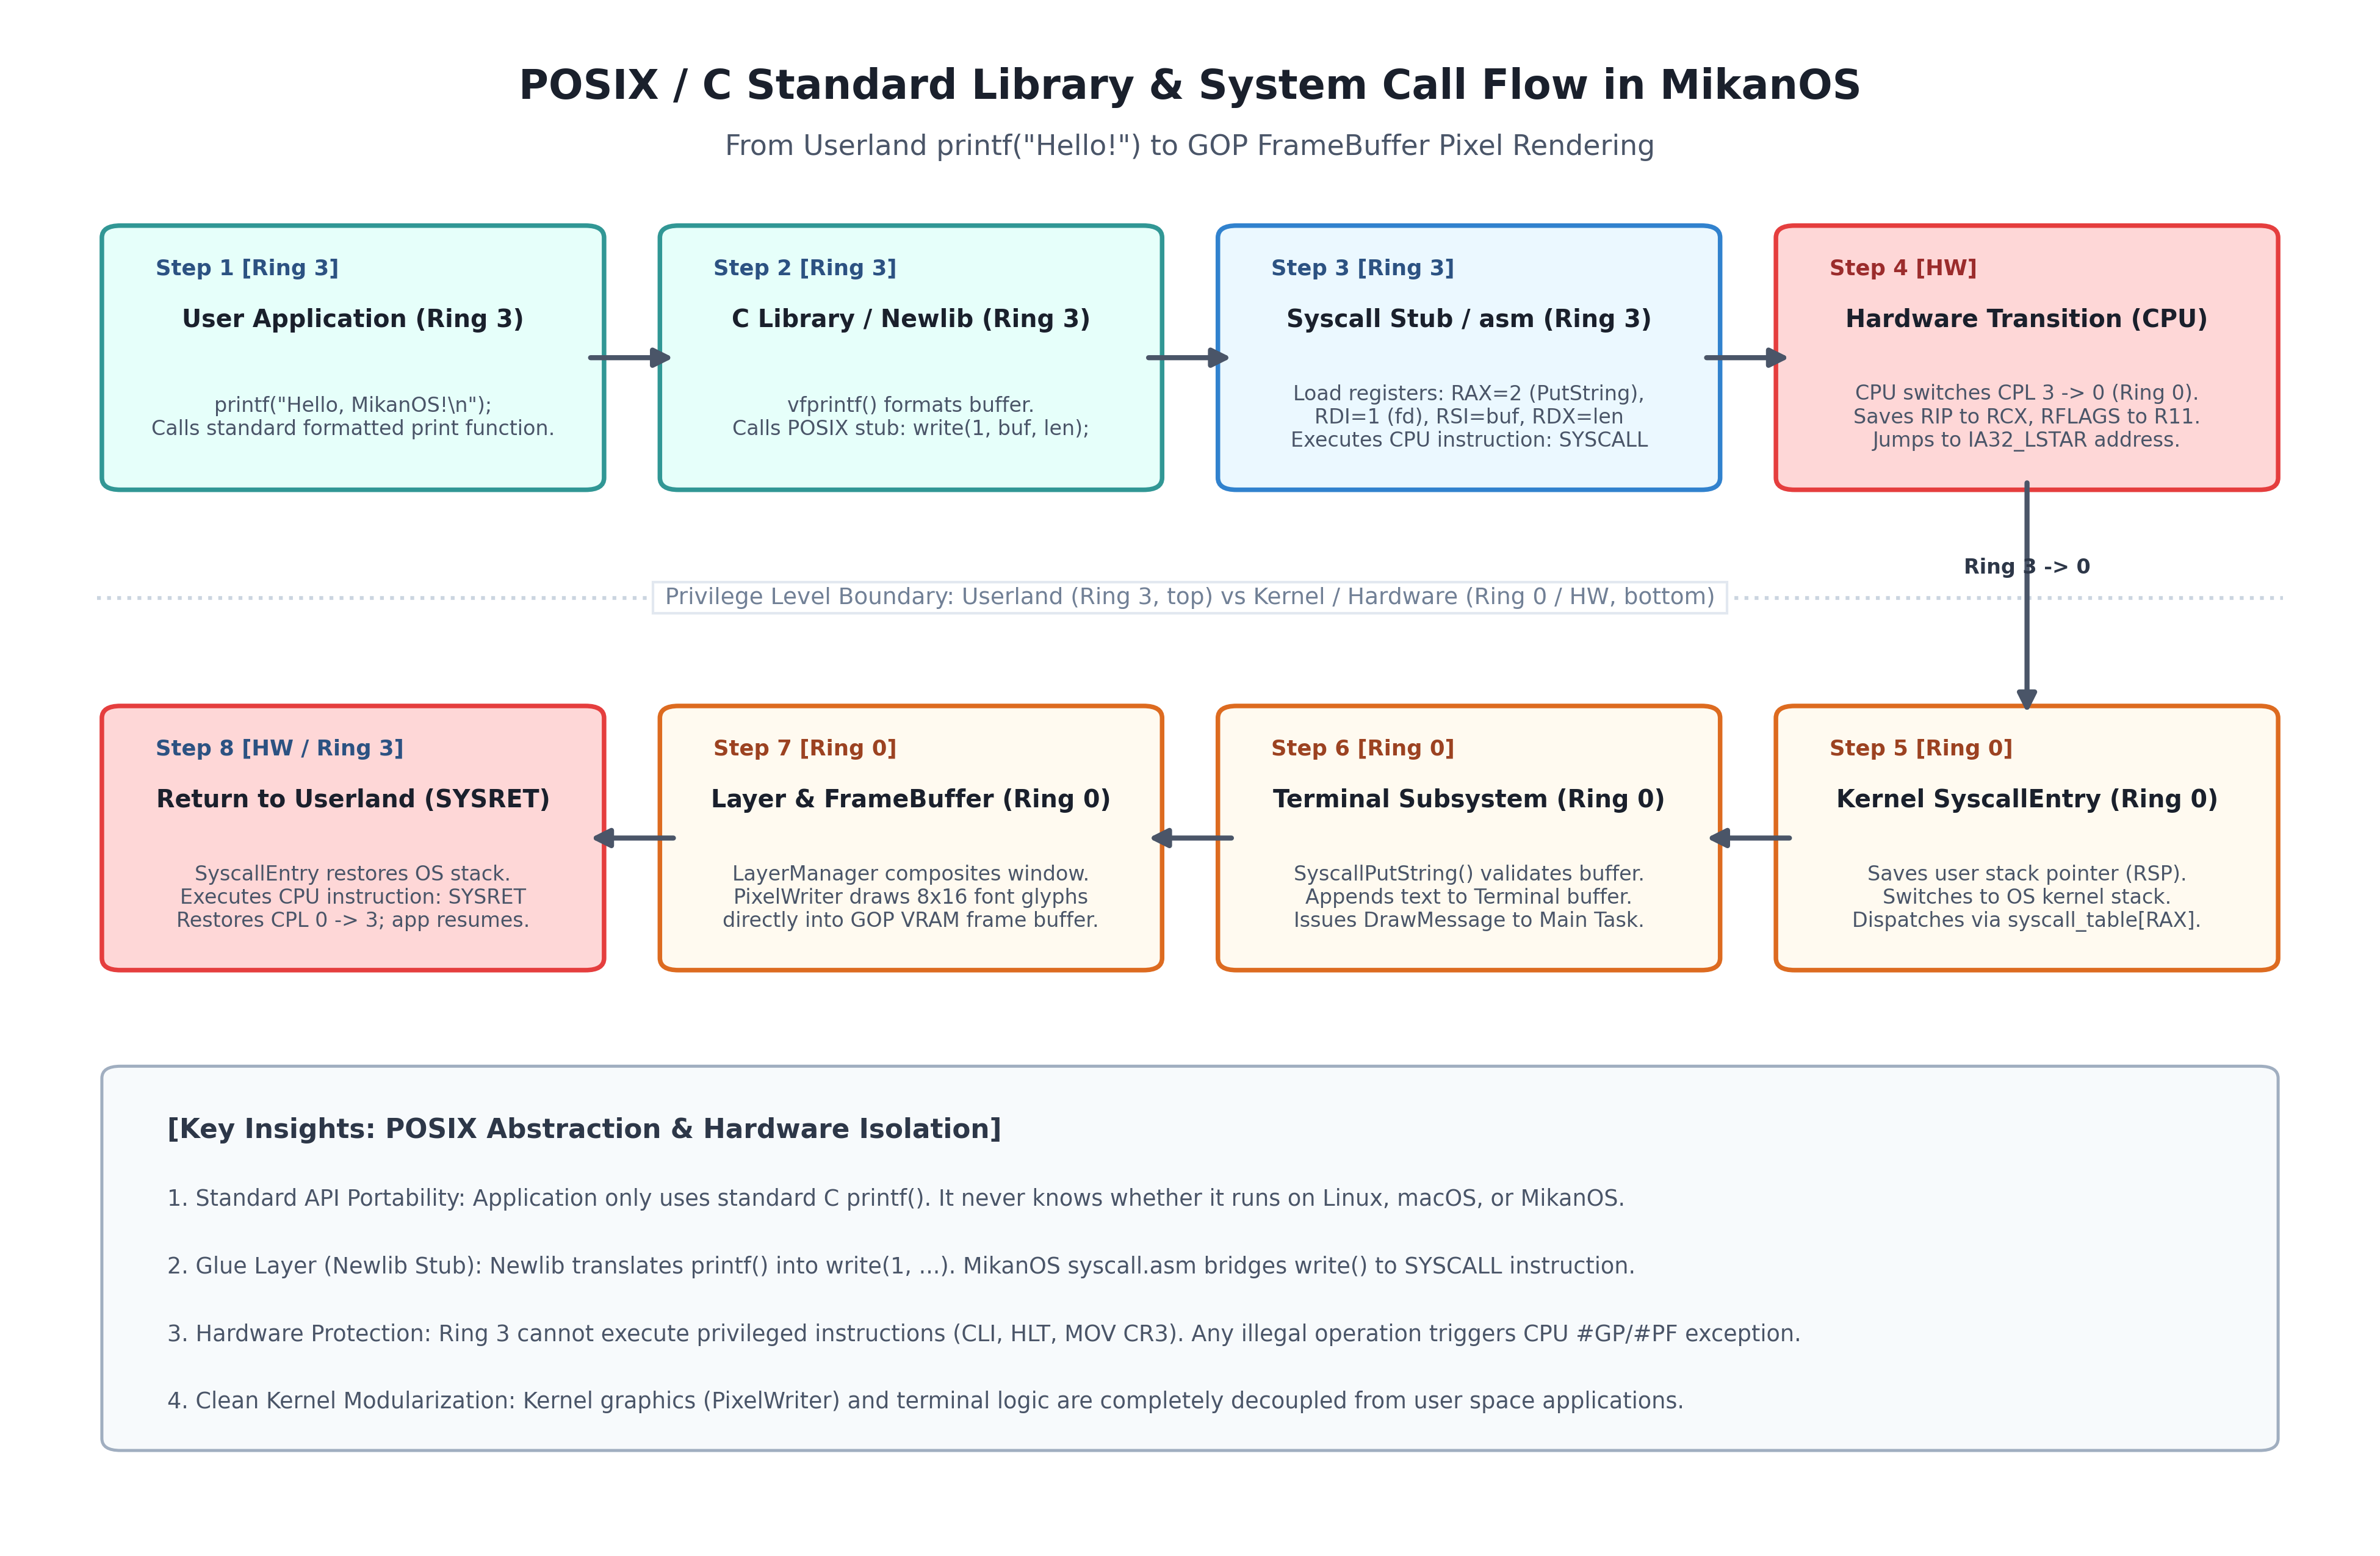

In [4]:
# 図版生成 2: POSIX/C標準ライブラリ（printf / write）からシステムコール（SYSCALL）への遷移フロー
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image, display

from common import setup_plot_style

setup_plot_style()
repo_root = Path.cwd().parent if Path.cwd().name == "0" else Path.cwd()
result_dir = repo_root / "0" / "result"
result_dir.mkdir(parents=True, exist_ok=True)
out_path = result_dir / "fig0_4_posix_system_call_flow.png"

fig, ax = plt.subplots(figsize=(13, 8.5), dpi=300)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Title
ax.text(50, 96, "POSIX / C Standard Library & System Call Flow in MikanOS",
        fontsize=16, fontweight="bold", ha="center", va="center", color="#1a202c")
ax.text(50, 92, "From Userland printf(\"Hello!\") to GOP FrameBuffer Pixel Rendering",
        fontsize=11, ha="center", va="center", color="#4a5568")

# Step Boxes
steps = [
    ("1", "User Application (Ring 3)", "printf(\"Hello, MikanOS!\\n\");\nCalls standard formatted print function.", 4, 70, 20, 16, "#e6fffa", "#319795", "Ring 3"),
    ("2", "C Library / Newlib (Ring 3)", "vfprintf() formats buffer.\nCalls POSIX stub: write(1, buf, len);", 28, 70, 20, 16, "#e6fffa", "#319795", "Ring 3"),
    ("3", "Syscall Stub / asm (Ring 3)", "Load registers: RAX=2 (PutString),\nRDI=1 (fd), RSI=buf, RDX=len\nExecutes CPU instruction: SYSCALL", 52, 70, 20, 16, "#ebf8ff", "#3182ce", "Ring 3"),
    ("4", "Hardware Transition (CPU)", "CPU switches CPL 3 -> 0 (Ring 0).\nSaves RIP to RCX, RFLAGS to R11.\nJumps to IA32_LSTAR address.", 76, 70, 20, 16, "#fed7d7", "#e53e3e", "HW"),

    ("5", "Kernel SyscallEntry (Ring 0)", "Saves user stack pointer (RSP).\nSwitches to OS kernel stack.\nDispatches via syscall_table[RAX].", 76, 38, 20, 16, "#fffaf0", "#dd6b20", "Ring 0"),
    ("6", "Terminal Subsystem (Ring 0)", "SyscallPutString() validates buffer.\nAppends text to Terminal buffer.\nIssues DrawMessage to Main Task.", 52, 38, 20, 16, "#fffaf0", "#dd6b20", "Ring 0"),
    ("7", "Layer & FrameBuffer (Ring 0)", "LayerManager composites window.\nPixelWriter draws 8x16 font glyphs\ndirectly into GOP VRAM frame buffer.", 28, 38, 20, 16, "#fffaf0", "#dd6b20", "Ring 0"),
    ("8", "Return to Userland (SYSRET)", "SyscallEntry restores OS stack.\nExecutes CPU instruction: SYSRET\nRestores CPL 0 -> 3; app resumes.", 4, 38, 20, 16, "#fed7d7", "#e53e3e", "HW / Ring 3"),
]

for num, title, desc, x, y, w, h, bg, border, ring in steps:
    box = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.8",
                                facecolor=bg, edgecolor=border, linewidth=1.8)
    ax.add_patch(box)
    badge = f"Step {num} [{ring}]"
    ax.text(x + 1.5, y + h - 2.5, badge, fontsize=8.5, fontweight="bold",
            color="#2c5282" if "Ring 3" in ring else ("#9c4221" if "Ring 0" in ring else "#9b2c2c"))
    ax.text(x + w/2, y + h - 5.5, title, fontsize=9.5, fontweight="bold", ha="center", va="center", color="#1a202c")
    ax.text(x + w/2, y + (h - 8)/2, desc, fontsize=8, ha="center", va="center", color="#4a5568")

# Arrows between steps
def draw_arrow(x1, y1, x2, y2, label=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", lw=2, color="#4a5568", mutation_scale=15))
    if label:
        ax.text((x1 + x2)/2, (y1 + y2)/2 + 2, label, fontsize=8, ha="center", va="center", color="#2d3748", fontweight="semibold")

draw_arrow(24, 78, 28, 78)
draw_arrow(48, 78, 52, 78)
draw_arrow(72, 78, 76, 78)
draw_arrow(86, 70, 86, 54, "Ring 3 -> 0")
draw_arrow(76, 46, 72, 46)
draw_arrow(52, 46, 48, 46)
draw_arrow(28, 46, 24, 46)

# Horizontal dividing line indicating Privilege boundary
ax.axhline(62, xmin=0.03, xmax=0.97, color="#cbd5e0", linestyle=":", linewidth=1.5)
ax.text(50, 62, " Privilege Level Boundary: Userland (Ring 3, top) vs Kernel / Hardware (Ring 0 / HW, bottom) ",
        fontsize=9, color="#718096", ha="center", va="center",
        bbox=dict(boxstyle="square,pad=0.2", facecolor="white", edgecolor="#e2e8f0"))

# Bottom Summary Card
rect_sum = patches.FancyBboxPatch((4, 6), 92, 24, boxstyle="round,pad=0.8",
                                  facecolor="#f7fafc", edgecolor="#a0aec0", linewidth=1.2)
ax.add_patch(rect_sum)
ax.text(6, 26, "[Key Insights: POSIX Abstraction & Hardware Isolation]", fontsize=10.5, fontweight="bold", color="#2d3748")
ax.text(6, 21.5, "1. Standard API Portability: Application only uses standard C printf(). It never knows whether it runs on Linux, macOS, or MikanOS.", fontsize=8.8, color="#4a5568")
ax.text(6, 17, "2. Glue Layer (Newlib Stub): Newlib translates printf() into write(1, ...). MikanOS syscall.asm bridges write() to SYSCALL instruction.", fontsize=8.8, color="#4a5568")
ax.text(6, 12.5, "3. Hardware Protection: Ring 3 cannot execute privileged instructions (CLI, HLT, MOV CR3). Any illegal operation triggers CPU #GP/#PF exception.", fontsize=8.8, color="#4a5568")
ax.text(6, 8, "4. Clean Kernel Modularization: Kernel graphics (PixelWriter) and terminal logic are completely decoupled from user space applications.", fontsize=8.8, color="#4a5568")

plt.tight_layout()
fig.savefig(out_path, dpi=300)
plt.close(fig)
print(f"Generated: {out_path} ({out_path.stat().st_size / 1024:.1f} KB)")
display(Image(filename=str(out_path)))


In [5]:
# Python (common.MockKernelSyscallDispatcher) によるシステムコールディスパッチ対話型シミュレーション
from common import MockKernelSyscallDispatcher, MIKANOS_SYSCALL_SPECS

dispatcher = MockKernelSyscallDispatcher()

print("=== MikanOS System Call Table Specifications ===")
for spec in MIKANOS_SYSCALL_SPECS[:6]:
    posix_tag = "[POSIX Standard]" if spec.is_posix_standard else "[MikanOS Specific]"
    print(f"Syscall #{spec.number:2d}: {spec.name:18s} | Registers: {spec.abi_register:25s} | {posix_tag}")

# 1. ユーザーランドからの PutString (syscall #2) 発行シミュレーション
ret1 = dispatcher.dispatch(syscall_num=2, arg1=1, arg2="Hello from Python Userland!\n")
ret2 = dispatcher.dispatch(syscall_num=2, arg1=1, arg2="MikanOS POSIX Abstraction in Action.\n")

print("\n--- [Kernel FrameBuffer Output Simulation] ---")
print(dispatcher.get_stdout(), end="")

# 2. エラー処理 (無効なファイルディスクリプタ: EBADF = -9)
bad_fd_ret = dispatcher.dispatch(syscall_num=2, arg1=999, arg2="Invalid text")
print(f"\nInvalid FD dispatch return code: {bad_fd_ret} (Expected: -9 / -EBADF)")

# 3. 未知のシステムコール番号 (ENOSYS = -38)
unknown_ret = dispatcher.dispatch(syscall_num=404, arg1=0, arg2="")
print(f"Unknown Syscall dispatch return code: {unknown_ret} (Expected: -38 / -ENOSYS)")

# 4. プロセス正常終了 (Exit: syscall #3)
exit_ret = dispatcher.dispatch(syscall_num=3, arg1=0, arg2="")
print(f"App Exit return code: {exit_ret} (Application successfully exited)")


=== MikanOS System Call Table Specifications ===
Syscall # 1: LogString          | Registers: RDI, RSI, RDX             | [MikanOS Specific]
Syscall # 2: PutString          | Registers: RDI, RSI, RDX             | [POSIX Standard]
Syscall # 3: Exit               | Registers: RDI                       | [POSIX Standard]
Syscall # 4: OpenWindow         | Registers: RDI, RSI, RDX, R10, R8    | [MikanOS Specific]
Syscall # 5: WinWriteString     | Registers: RDI, RSI, RDX, R10, R8    | [MikanOS Specific]
Syscall # 6: WinFillRectangle   | Registers: RDI, RSI, RDX, R10, R8, R9 | [MikanOS Specific]

--- [Kernel FrameBuffer Output Simulation] ---
Hello from Python Userland!
MikanOS POSIX Abstraction in Action.

Invalid FD dispatch return code: -9 (Expected: -9 / -EBADF)
Unknown Syscall dispatch return code: -38 (Expected: -38 / -ENOSYS)
App Exit return code: 0 (Application successfully exited)


---

## 2. まとめと次節への橋渡し

本節では、オペレーティングシステムの根源的な存在意義とアーキテクチャについて学びました。

### 本節の重要ポイント
1. **ハードウェアの抽象化**: メーカーや型番によって異なる複雑なハードウェア制御手順をデバイスドライバ内に隠蔽し、アプリケーションには統一的でシンプルな API（ファイル、バイトストリーム等）を提供する。
2. **リソースの管理**: 複数のプログラムが並行動作する際、メモリ破壊やCPU時間の独占、画面表示の衝突を防ぐため、仮想記憶（ページング）、マルチタスク（スケジューラ）、レイヤマネージャによって厳格に調停・保護する。
3. **特権分離 (Ring 0 vs Ring 3)**: CPU ハードウェアが提供する特権レベルにより、OS カーネル（Ring 0）と一般アプリケーション（Ring 3）を物理的に分離し、バグや悪意ある操作からシステム全体を防護する。
4. **POSIX と Newlib**: 国際標準仕様 POSIX に準拠した C 標準ライブラリ（Newlib）を採用することで、フルスクラッチ自作 OS でありながら標準的な C/C++ 言語のコード資産や開発知識をそのまま活用できる。

### 次節への橋渡し
OS の存在意義とアーキテクチャが明らかになったところで、次節 **「0.3 OS自作の手順 (*Steps to Build an OS*)」** では、実際に人間が書いたソースコード（C++ やアセンブリ）がどのようなツールチェイン（コンパイラ・リンカ）を経て機械語バイナリとなり、どのようにブートメディア（USB メモリ等）に書き込まれて PC を起動させるのか、その具体的な開発プロセスと起動シーケンスを解き明かします！
